Executive Inventory KPI Dashboard

Objectives

1. Build inventory health metrics
2. Track forecasting performance
3. Measure availability
4. Monitor working capital
5. Generate executive scorecards
"""

In [1]:
## Imports

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

In [2]:
## Sample KPI Dataset

dashboard_df = pd.DataFrame({

    "Region":[
        "North",
        "South",
        "East",
        "West"
    ],

    "Sales":[
        500000,
        450000,
        520000,
        490000
    ],

    "Inventory":[
        250000,
        320000,
        260000,
        280000
    ],

    "Forecast_Accuracy":[
        92,
        88,
        95,
        90
    ],

    "In_Stock":[
        98,
        95,
        99,
        96
    ]

})

display(dashboard_df)

,Region,Sales,Inventory,Forecast_Accuracy,In_Stock
0,North,500000,250000,92,98
1,South,450000,320000,88,95
2,East,520000,260000,95,99
3,West,490000,280000,90,96


In [3]:
## Calculate Inventory Turns

dashboard_df["Inventory_Turns"] = (
    dashboard_df["Sales"] /
    dashboard_df["Inventory"]
)

display(dashboard_df)

,Region,Sales,Inventory,Forecast_Accuracy,In_Stock,Inventory_Turns
0,North,500000,250000,92,98,2.00000
1,South,450000,320000,88,95,1.40625
2,East,520000,260000,95,99,2.00000
3,West,490000,280000,90,96,1.75000


In [4]:
## Calculate Weeks of Supply

dashboard_df["Weekly_Demand"] = (
    dashboard_df["Sales"] / 52
)

dashboard_df["Weeks_of_Supply"] = (
    dashboard_df["Inventory"] /
    dashboard_df["Weekly_Demand"]
)

display(dashboard_df)

,Region,Sales,Inventory,Forecast_Accuracy,In_Stock,Inventory_Turns,Weekly_Demand,Weeks_of_Supply
0,North,500000,250000,92,98,2.00000,9615.384615,26.000000
1,South,450000,320000,88,95,1.40625,8653.846154,36.977778
2,East,520000,260000,95,99,2.00000,10000.000000,26.000000
3,West,490000,280000,90,96,1.75000,9423.076923,29.714286


In [5]:
## KPI Summary

kpi_summary = pd.DataFrame({

    "Metric":[
        "Total Sales",
        "Total Inventory",
        "Avg Forecast Accuracy",
        "Avg In Stock"
    ],

    "Value":[
        dashboard_df["Sales"].sum(),
        dashboard_df["Inventory"].sum(),
        dashboard_df["Forecast_Accuracy"].mean(),
        dashboard_df["In_Stock"].mean()
    ]

})

display(kpi_summary)


,Metric,Value
0,Total Sales,1960000.00
1,Total Inventory,1110000.00
2,Avg Forecast Accuracy,91.25
3,Avg In Stock,97.00


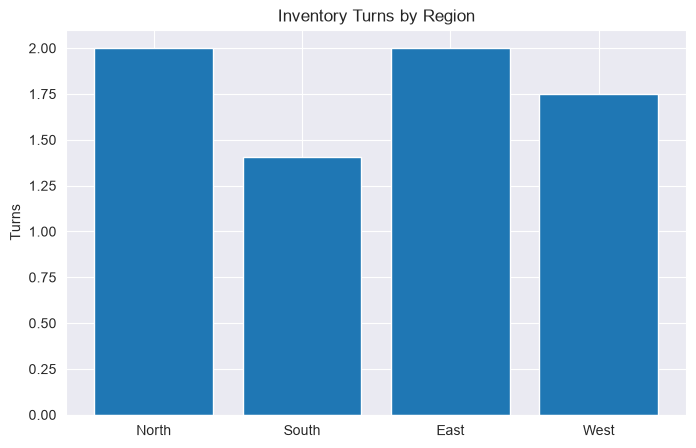

In [6]:
## Inventory Turns Chart

plt.figure(figsize=(8,5))

plt.bar(
    dashboard_df["Region"],
    dashboard_df["Inventory_Turns"]
)

plt.title("Inventory Turns by Region")
plt.ylabel("Turns")

plt.show()

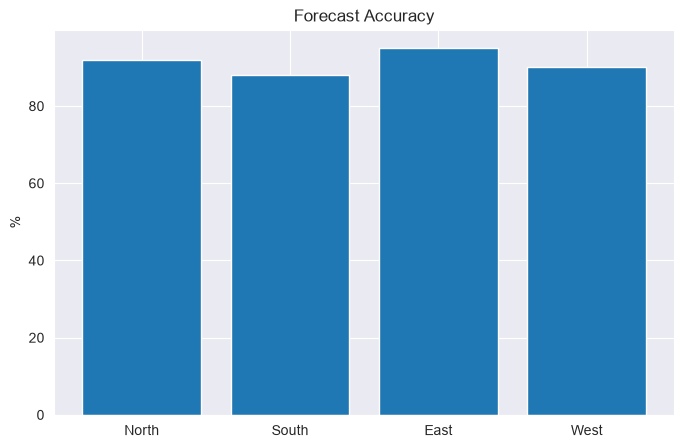

In [7]:
## Forecast Accuracy Chart

plt.figure(figsize=(8,5))

plt.bar(
    dashboard_df["Region"],
    dashboard_df["Forecast_Accuracy"]
)

plt.title("Forecast Accuracy")
plt.ylabel("%")

plt.show()

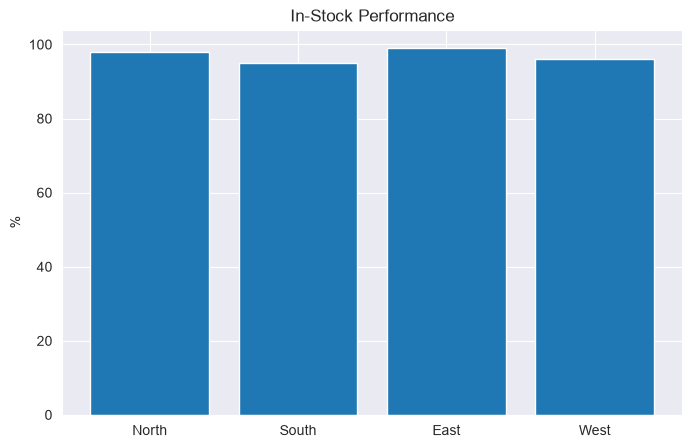

In [8]:
## In-Stock Performance

plt.figure(figsize=(8,5))

plt.bar(
    dashboard_df["Region"],
    dashboard_df["In_Stock"]
)

plt.title("In-Stock Performance")
plt.ylabel("%")

plt.show()

In [9]:
## Inventory Risk Classification

dashboard_df["Risk_Level"] = np.where(

    dashboard_df["Weeks_of_Supply"] > 30,

    "High Risk",

    "Normal"

)

display(dashboard_df)

,Region,Sales,Inventory,Forecast_Accuracy,In_Stock,Inventory_Turns,Weekly_Demand,Weeks_of_Supply,Risk_Level
0,North,500000,250000,92,98,2.00000,9615.384615,26.000000,Normal
1,South,450000,320000,88,95,1.40625,8653.846154,36.977778,High Risk
2,East,520000,260000,95,99,2.00000,10000.000000,26.000000,Normal
3,West,490000,280000,90,96,1.75000,9423.076923,29.714286,Normal


In [10]:
## Identify Weakest Region

weakest_region = dashboard_df.loc[
    dashboard_df["Forecast_Accuracy"].idxmin()
]

weakest_region

Region                     South
Sales                     450000
Inventory                 320000
Forecast_Accuracy             88
In_Stock                      95
Inventory_Turns          1.40625
Weekly_Demand        8653.846154
Weeks_of_Supply        36.977778
Risk_Level             High Risk
Name: 1, dtype: object

In [11]:
## Working Capital Opportunity

dashboard_df["Potential_Reduction"] = (
    dashboard_df["Inventory"] * 0.10
)

dashboard_df[
    ["Region","Potential_Reduction"]
]

,Region,Potential_Reduction
0,North,25000.0
1,South,32000.0
2,East,26000.0
3,West,28000.0


In [12]:
## Executive Insights

print("EXECUTIVE INSIGHTS")

print()

print(
    f"Total Inventory = "
    f"${dashboard_df['Inventory'].sum():,.0f}"
)

print(
    f"Average Forecast Accuracy = "
    f"{dashboard_df['Forecast_Accuracy'].mean():.1f}%"
)

print(
    f"Average In-Stock = "
    f"{dashboard_df['In_Stock'].mean():.1f}%"
)

EXECUTIVE INSIGHTS

Total Inventory = $1,110,000
Average Forecast Accuracy = 91.2%
Average In-Stock = 97.0%


In [13]:
## Management Recommendations

recommendations = [

    "Improve forecast accuracy in weak regions",

    "Reduce excess inventory",

    "Increase inventory turns",

    "Maintain 98%+ in-stock levels",

    "Optimize replenishment parameters"

]

for rec in recommendations:
    print("-", rec)

- Improve forecast accuracy in weak regions
- Reduce excess inventory
- Increase inventory turns
- Maintain 98%+ in-stock levels
- Optimize replenishment parameters


In [14]:
## Executive Scorecard

scorecard = dashboard_df[[

    "Region",
    "Sales",
    "Inventory",
    "Inventory_Turns",
    "Weeks_of_Supply",
    "Forecast_Accuracy",
    "In_Stock",
    "Risk_Level"

]]

display(scorecard)

,Region,Sales,Inventory,Inventory_Turns,Weeks_of_Supply,Forecast_Accuracy,In_Stock,Risk_Level
0,North,500000,250000,2.00000,26.000000,92,98,Normal
1,South,450000,320000,1.40625,36.977778,88,95,High Risk
2,East,520000,260000,2.00000,26.000000,95,99,Normal
3,West,490000,280000,1.75000,29.714286,90,96,Normal


In [15]:
## Key Takeaways

print("""
KEY TAKEAWAYS

1. Inventory turns drive working capital efficiency

2. Forecast accuracy directly impacts inventory

3. In-stock performance drives customer experience

4. Excess inventory creates financial risk

5. KPI dashboards support executive decision making
""")


KEY TAKEAWAYS

1. Inventory turns drive working capital efficiency

2. Forecast accuracy directly impacts inventory

3. In-stock performance drives customer experience

4. Excess inventory creates financial risk

5. KPI dashboards support executive decision making

